Saving push-back-tow-truck-plane-at-the-airport-airport-terminal-view-other-aircraft-typical-aviation-life-work-2FK0DPE.jpg to push-back-tow-truck-plane-at-the-airport-airport-terminal-view-other-aircraft-typical-aviation-life-work-2FK0DPE.jpg


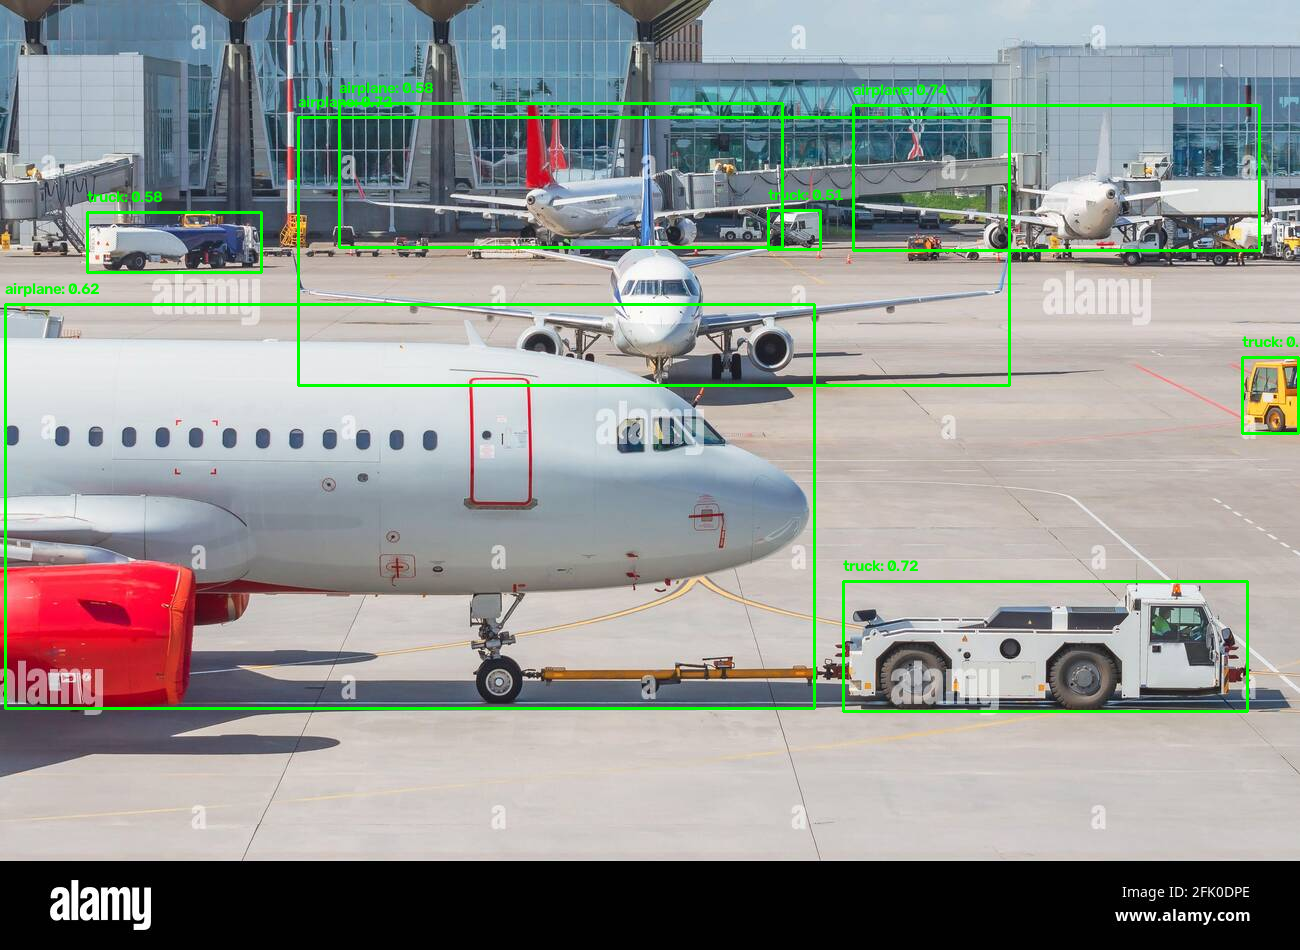

In [4]:
# ---------------------------------------------------------------------------
# 1. IMPORTS
# ---------------------------------------------------------------------------
import cv2  # OpenCV: open images, draw boxes
from google.colab import files
from google.colab.patches import cv2_imshow  # Colab’s replacement for cv2.imshow
import numpy as np  # for working with number arrays
import tensorflow as tf  # the deep-learning engine
import tensorflow_hub as hub  # to download the ready-trained model

# ---------------------------------------------------------------------------
# 2. LOAD THE PRE-TRAINED DETECTOR
# ---------------------------------------------------------------------------
MODEL_URL = "https://tfhub.dev/tensorflow/efficientdet/d7/1"
detector = hub.load(MODEL_URL)

# ---------------------------------------------------------------------------
# 3. CLASS NAMES - COCO Dataset Category Mapping (1-indexed alignment)
# ---------------------------------------------------------------------------
COCO_CLASSES = {
    1: "person",
    2: "bicycle",
    3: "car",
    4: "motorcycle",
    5: "airplane",
    6: "bus",
    7: "train",
    8: "truck",
    9: "boat",
    10: "traffic light",
    11: "fire hydrant",
    13: "stop sign",
    14: "parking meter",
    15: "bench",
    16: "bird",
    17: "cat",
    18: "dog",
    19: "horse",
    20: "sheep",
    21: "cow",
    22: "elephant",
    23: "bear",
    24: "zebra",
    25: "giraffe",
    27: "backpack",
    28: "umbrella",
    31: "handbag",
    32: "tie",
    33: "suitcase",
    34: "frisbee",
    35: "skis",
    36: "snowboard",
    37: "sports ball",
    38: "kite",
    39: "baseball bat",
    40: "baseball glove",
    41: "skateboard",
    42: "surfboard",
    43: "tennis racket",
    44: "bottle",
    46: "wine glass",
    47: "cup",
    48: "fork",
    49: "knife",
    50: "spoon",
    51: "bowl",
    52: "banana",
    53: "apple",
    54: "sandwich",
    55: "orange",
    56: "broccoli",
    57: "carrot",
    58: "hot dog",
    59: "pizza",
    60: "donut",
    61: "cake",
    62: "chair",
    63: "couch",
    64: "potted plant",
    65: "bed",
    67: "dining table",
    70: "toilet",
    72: "tv",
    73: "laptop",
    74: "mouse",
    75: "remote",
    76: "keyboard",
    77: "cell phone",
    78: "microwave",
    79: "oven",
    80: "toaster",
    81: "sink",
    82: "refrigerator",
    84: "book",
    85: "clock",
    86: "vase",
    87: "scissors",
    88: "teddy bear",
    89: "hair drier",
    90: "toothbrush",
}


def detect_objects_with_boxes(image_path, detector):
    """Run the detector on one image and return the image with boxes drawn."""
    image = cv2.imread(image_path)
    if image is None:
        raise ValueError(f"Could not load image at {image_path}")

    orig_image = image.copy()

    # Convert BGR (OpenCV default) to RGB (TensorFlow expected format)
    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Convert to uint8 tensor and add batch dimension [1, H, W, 3]
    input_tensor = tf.convert_to_tensor(rgb_image, dtype=tf.uint8)
    input_tensor = input_tensor[tf.newaxis, ...]

    # Run object detection model
    detections = detector(input_tensor)

    num_detections = int(detections["num_detections"])
    detection_boxes = detections["detection_boxes"].numpy()[0]
    detection_classes = detections["detection_classes"].numpy()[0].astype(
        np.int32
    )
    detection_scores = detections["detection_scores"].numpy()[0]

    confidence_threshold = 0.5

    for i in range(num_detections):
        score = detection_scores[i]
        if score > confidence_threshold:
            box = detection_boxes[i]
            h, w, _ = orig_image.shape

            # Extract box coordinates (y_min, x_min, y_max, x_max) normalized [0, 1]
            y_min, x_min, y_max, x_max = box
            x_min, x_max = int(x_min * w), int(x_max * w)
            y_min, y_max = int(y_min * h), int(y_max * h)

            class_id = detection_classes[i]
            class_name = COCO_CLASSES.get(class_id, "Unknown")
            label = f"{class_name}: {score:.2f}"

            # Draw bounding box and text on the original BGR image
            cv2.rectangle(
                orig_image, (x_min, y_min), (x_max, y_max), (0, 255, 0), 2
            )
            cv2.putText(
                orig_image,
                label,
                (x_min, max(y_min - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (0, 255, 0),
                2,
            )

    return orig_image


# ---------------------------------------------------------------------------
# 4. RUN DETECTOR
# ---------------------------------------------------------------------------
uploaded = files.upload()
image_path = next(iter(uploaded))
result_image = detect_objects_with_boxes(image_path, detector)
cv2_imshow(result_image)

Saving push-back-tow-truck-plane-at-the-airport-airport-terminal-view-other-aircraft-typical-aviation-life-work-2FK0DPE.jpg to push-back-tow-truck-plane-at-the-airport-airport-terminal-view-other-aircraft-typical-aviation-life-work-2FK0DPE (2).jpg


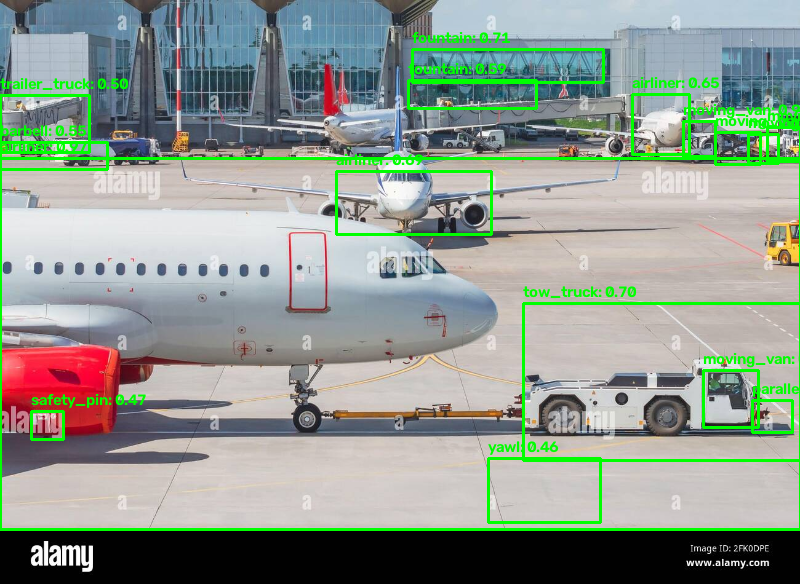

In [2]:
# ---------------------------------------------------------------------------
# 0. SETUP (run once) - install OpenCV with Selective Search, then auto-restart.
# ---------------------------------------------------------------------------
import os
import subprocess

try:
    import cv2
    ss_ready = hasattr(cv2, "ximgproc") and hasattr(cv2.ximgproc, "segmentation")
except Exception:
    ss_ready = False

if not ss_ready:
    subprocess.run(
        "pip uninstall -y -q opencv-python opencv-python-headless "
        "opencv-contrib-python opencv-contrib-python-headless",
        shell=True,
    )
    subprocess.run("pip install -q opencv-contrib-python", shell=True)
    os.kill(os.getpid(), 9)

# ---------------------------------------------------------------------------
# 1. IMPORTS
# ---------------------------------------------------------------------------
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import (
    decode_predictions,
    preprocess_input,
)

# ---------------------------------------------------------------------------
# 2. CLASSIFIER: VGG16 pre-trained on ImageNet
# ---------------------------------------------------------------------------
model = VGG16(weights="imagenet", include_top=True)

# ---------------------------------------------------------------------------
# 3. REGION PROPOSALS
# ---------------------------------------------------------------------------
def get_region_proposals(img, max_regions=300):
    try:
        ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
        ss.setBaseImage(img)
        ss.switchToSelectiveSearchFast()
        boxes = [
            (x, y, w, h) for (x, y, w, h) in ss.process() if w > 25 and h > 25
        ]
        if boxes:
            return boxes[:max_regions]
    except Exception:
        pass

    # Fallback: expanded multi-scale sliding windows
    H, W = img.shape[:2]
    boxes = []
    for s in (0.5, 0.35, 0.2, 0.1):
        bw, bh = int(W * s), int(H * s)
        for y in range(0, H - bh + 1, max(1, bh // 2)):
            for x in range(0, W - bw + 1, max(1, bw // 2)):
                boxes.append((x, y, bw, bh))
    return boxes[:max_regions]

# ---------------------------------------------------------------------------
# 4. NON-MAXIMUM SUPPRESSION (Corrected Math)
# ---------------------------------------------------------------------------
def non_max_suppression(dets, iou_thr=0.3):
    if not dets:
        return []

    boxes = np.array(
        [[x, y, x + w, y + h] for (x, y, w, h), _, _ in dets], dtype=float
    )
    scores = np.array([s for _, _, s in dets])
    order = scores.argsort()[::-1]
    keep = []

    while len(order) > 0:
        i = order[0]
        keep.append(i)
        rest = order[1:]

        xx1 = np.maximum(boxes[i, 0], boxes[rest, 0])
        yy1 = np.maximum(boxes[i, 1], boxes[rest, 1])
        xx2 = np.minimum(boxes[i, 2], boxes[rest, 2])
        yy2 = np.minimum(boxes[i, 3], boxes[rest, 3])

        w = np.clip(xx2 - xx1, 0, None)
        h = np.clip(yy2 - yy1, 0, None)
        inter = w * h

        # FIXED: Corrected subtraction math for bounding box areas
        area_i = (boxes[i, 2] - boxes[i, 0]) * (boxes[i, 3] - boxes[i, 1])
        area_r = (boxes[rest, 2] - boxes[rest, 0]) * (boxes[rest, 3] - boxes[rest, 1])

        iou = inter / (area_i + area_r - inter + 1e-9)
        order = rest[iou < iou_thr]

    return [dets[i] for i in keep]

# ---------------------------------------------------------------------------
# 5. RUN DETECTION PIPELINE
# ---------------------------------------------------------------------------
uploaded = files.upload()
image_path = next(iter(uploaded))
img = cv2.imread(image_path)
H0, W0 = img.shape[:2]
img = cv2.resize(img, (800, int(H0 * 800.0 / W0)))  # Slightly higher resolution for small objects

boxes = get_region_proposals(img, max_regions=300)

crop_list = []
for x, y, w, h in boxes:
    crop = img[y : y + h, x : x + w].copy()
    crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
    crop_resized = cv2.resize(crop_rgb, (224, 224))
    crop_list.append(crop_resized)

if crop_list:
    crops = np.array(crop_list, dtype=np.float32)
    preprocessed_crops = preprocess_input(crops)
    preds = model.predict(preprocessed_crops, batch_size=32, verbose=0)

    detections = []
    for (x, y, w, h), p in zip(boxes, preds):
        _, label, prob = decode_predictions(p[None], top=1)[0][0]
        # Lower threshold to pick up secondary objects (0.45 vs 0.90)
        if prob > 0.45:
            detections.append(((x, y, w, h), label, float(prob)))

    detections = non_max_suppression(detections, iou_thr=0.3)

    for (x, y, w, h), label, score in detections:
        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(
            img,
            f"{label}: {score:.2f}",
            (x, max(18, y - 6)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            2,
        )

cv2_imshow(img)